# CT118-3-3 — Assignment 1, Task 2: Data Preparation & EDA
## Miami Housing Dataset

This notebook works through Exploratory Data Analysis (EDA) and pre-processing for the Miami Housing Dataset, in preparation for the deep learning models to be built in Assignment 2.

**Before running:** place `miami-housing.csv` (or your renamed file) in the same folder as this notebook, and update the filename in Step 1 if needed.


## Step 0: Import Libraries

We import the libraries needed for data handling (`pandas`, `numpy`), visualisation (`matplotlib`, `seaborn`), and pre-processing (`scikit-learn`). Doing this in one place at the top keeps the notebook organised and makes dependencies clear to anyone reading it.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)


## Step 1: Load Data & Initial Inspection

We load the CSV and perform a first inspection — checking the shape, data types, and summary statistics. This step is essential before any cleaning, as it tells us what we're actually working with (how many rows/columns, which columns are numeric vs categorical, and whether any data types look wrong, e.g. a numeric column read in as text).


In [2]:
df = pd.read_csv('miami-housing.csv')  # update filename if different

print("Shape (rows, columns):", df.shape)
df.head()


Shape (rows, columns): (13932, 17)


,LATITUDE,LONGITUDE,PARCELNO,SALE_PRC,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality
0,25.891031,-80.160561,622280070620,440000.0,9375,1753,0,2815.9,12811.4,347.6,42815.3,37742.2,15954.9,67,0,8,4
1,25.891324,-80.153968,622280100460,349000.0,9375,1715,0,4359.1,10648.4,337.8,43504.9,37340.5,18125.0,63,0,9,4
2,25.891334,-80.153740,622280100470,800000.0,9375,2276,49206,4412.9,10574.1,297.1,43530.4,37328.7,18200.5,61,0,2,4
3,25.891765,-80.152657,622280100530,988000.0,12450,2058,10033,4585.0,10156.5,0.0,43797.5,37423.2,18514.4,63,0,9,4
4,25.891825,-80.154639,622280100200,755000.0,12800,1684,16681,4063.4,10836.8,326.6,43599.7,37550.8,17903.4,42,0,7,4


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 13932 entries, 0 to 13931
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   LATITUDE           13932 non-null  float64
 1   LONGITUDE          13932 non-null  float64
 2   PARCELNO           13932 non-null  int64  
 3   SALE_PRC           13932 non-null  float64
 4   LND_SQFOOT         13932 non-null  int64  
 5   TOT_LVG_AREA       13932 non-null  int64  
 6   SPEC_FEAT_VAL      13932 non-null  int64  
 7   RAIL_DIST          13932 non-null  float64
 8   OCEAN_DIST         13932 non-null  float64
 9   WATER_DIST         13932 non-null  float64
 10  CNTR_DIST          13932 non-null  float64
 11  SUBCNTR_DI         13932 non-null  float64
 12  HWY_DIST           13932 non-null  float64
 13  age                13932 non-null  int64  
 14  avno60plus         13932 non-null  int64  
 15  month_sold         13932 non-null  int64  
 16  structure_quality  13932 non-null

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
LATITUDE,13932.0,2.572881e+01,1.406333e-01,2.543433e+01,2.562006e+01,2.573181e+01,2.585227e+01,2.597438e+01
LONGITUDE,13932.0,-8.032748e+01,8.919907e-02,-8.054217e+01,-8.040328e+01,-8.033891e+01,-8.025802e+01,-8.011975e+01
PARCELNO,13932.0,2.356496e+12,1.199290e+12,1.020008e+11,1.079160e+12,3.040300e+12,3.060170e+12,3.660170e+12
SALE_PRC,13932.0,3.999419e+05,3.172147e+05,7.200000e+04,2.350000e+05,3.100000e+05,4.280000e+05,2.650000e+06
LND_SQFOOT,13932.0,8.620880e+03,6.070089e+03,1.248000e+03,5.400000e+03,7.500000e+03,9.126250e+03,5.706400e+04
TOT_LVG_AREA,13932.0,2.058045e+03,8.135385e+02,8.540000e+02,1.470000e+03,1.877500e+03,2.471000e+03,6.287000e+03
SPEC_FEAT_VAL,13932.0,9.562493e+03,1.389097e+04,0.000000e+00,8.100000e+02,2.765500e+03,1.235225e+04,1.750200e+05
RAIL_DIST,13932.0,8.348549e+03,6.178027e+03,1.050000e+01,3.299450e+03,7.106300e+03,1.210260e+04,2.962150e+04
OCEAN_DIST,13932.0,3.169099e+04,1.759508e+04,2.361000e+02,1.807935e+04,2.854175e+04,4.431065e+04,7.574490e+04
WATER_DIST,13932.0,1.196029e+04,1.193299e+04,0.000000e+00,2.675850e+03,6.922600e+03,1.920000e+04,5.039980e+04


**What to note down:**
- Total number of rows and columns — confirm it matches the ~13,932 records / 17 features described in the dataset documentation.
- Any column with an unexpected data type (e.g. a numeric column showing as `object`).
- From `.describe()`: note the **min/max of SALE_PRC** (are there implausible values like $0 or extremely high outlier prices?), and scan other columns for suspicious min/max values (e.g. negative distances, which shouldn't exist).


## Step 2: Handle Duplicate Records (PARCELNO)

The dataset documentation notes that `PARCELNO` (the unique property identifier) appears more than once for about 1% of records. Here we quantify this and decide how to handle it — duplicates could indicate genuine repeat sales (kept) or data entry errors (candidates for removal), so we inspect before deciding.


In [5]:
dup_counts = df['PARCELNO'].value_counts()
repeated_parcels = dup_counts[dup_counts > 1]

print(f"Number of unique PARCELNO values: {df['PARCELNO'].nunique()}")
print(f"Number of PARCELNO values appearing more than once: {len(repeated_parcels)}")
print(f"Percentage of repeated parcels: {len(repeated_parcels) / df['PARCELNO'].nunique() * 100:.2f}%")

# Inspect a few repeated parcels to understand whether they are genuine repeat sales
df[df['PARCELNO'].isin(repeated_parcels.index[:3])].sort_values('PARCELNO')


Number of unique PARCELNO values: 13776
Number of PARCELNO values appearing more than once: 152
Percentage of repeated parcels: 1.10%


,LATITUDE,LONGITUDE,PARCELNO,SALE_PRC,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality
2351,25.816591,-80.198387,131240200610,180000.0,7200,1742,2394,2743.4,24820.4,4322.4,14557.6,14557.6,1780.8,76,0,3,2
2352,25.816591,-80.198387,131240200610,190000.0,7200,1742,2394,2743.4,24820.4,4322.4,14557.6,14557.6,1780.8,76,0,5,2
2353,25.816591,-80.198387,131240200610,270000.0,7200,1742,2394,2743.4,24820.4,4322.4,14557.6,14557.6,1780.8,76,0,7,2
164,25.908080,-80.167954,3022200023090,148900.0,9900,1556,0,2973.7,15183.3,3424.0,48378.1,44362.6,13752.4,61,0,9,1
166,25.908080,-80.167954,3022200023090,177500.0,9900,1556,0,2973.7,15183.3,3424.0,48378.1,44362.6,13752.4,61,0,9,1
165,25.908080,-80.167954,3022200023090,158000.0,9900,1556,0,2973.7,15183.3,3424.0,48378.1,44362.6,13752.4,61,0,9,1
2080,25.837536,-80.228887,3031150056160,105000.0,4000,959,892,1113.3,33545.3,8162.6,25074.0,25074.0,7523.2,28,0,4,2
2078,25.837536,-80.228887,3031150056160,72000.0,4000,959,892,1113.3,33545.3,8162.6,25074.0,25074.0,7523.2,28,0,1,2
2079,25.837536,-80.228887,3031150056160,90000.0,4000,959,892,1113.3,33545.3,8162.6,25074.0,25074.0,7523.2,28,0,2,2


In [6]:
# Example handling: if repeated parcels represent repeat sales at different prices/dates,
# it is reasonable to KEEP them (each row is still a valid, distinct transaction).
# If instead they look like exact duplicate rows, drop the duplicates.

exact_duplicates = df.duplicated().sum()
print(f"Number of fully duplicated rows (all columns identical): {exact_duplicates}")

df = df.drop_duplicates()
print(f"Shape after dropping exact duplicate rows: {df.shape}")


Number of fully duplicated rows (all columns identical): 0
Shape after dropping exact duplicate rows: (13932, 17)


**What to note down:**
- The exact percentage of repeated `PARCELNO` values (confirm it's close to the ~1% mentioned in the dataset description).
- Whether repeated parcels have **different** `SALE_PRC`/`month_sold` values (→ genuine repeat sales, keep them) or are **identical** across all columns (→ true duplicates, safe to drop).
- Final row count after this step — you'll reference this in your report as your "cleaned" dataset size.


## Step 3: Missing Value Analysis

We check every column for missing values. Neural networks cannot train on missing values directly, so any gaps must be identified now and handled (via imputation or row removal) before modelling. This dataset is generally clean, but this step should still be reported explicitly, even if the result is "no missing values found."


In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_summary = pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct})
missing_summary = missing_summary[missing_summary['missing_count'] > 0].sort_values('missing_%', ascending=False)

print("Columns with missing values:")
missing_summary if not missing_summary.empty else print("No missing values found in any column.")


Columns with missing values:
No missing values found in any column.


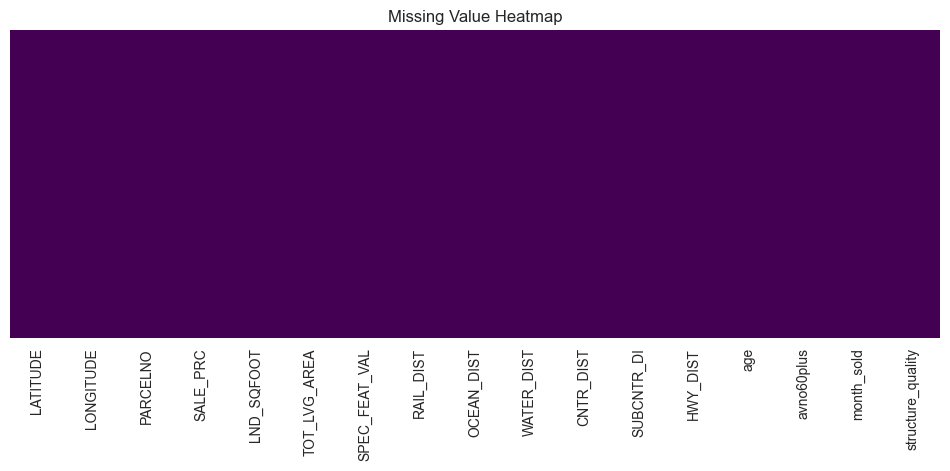

In [8]:
# Visualise missingness (useful even if the result is "all zero" — it's evidence for your report)
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Value Heatmap')
plt.show()


**What to note down:**
- Whether any columns have missing values, and if so, what percentage.
- If missing values exist: decide and justify a strategy per column (e.g. drop rows if <1% missing, median imputation for skewed numeric columns, mode imputation for categorical columns).
- If no missing values are found (likely for this dataset): explicitly state this in your report — it's still a required part of the EDA, not something to skip.


## Step 4: Target Variable Analysis (SALE_PRC)

Before analysing predictor features, we examine the distribution of the target variable itself. Price data is typically right-skewed (many moderately priced homes, a few very expensive ones), which can affect model training — this step checks whether a transformation (e.g. log) is needed.


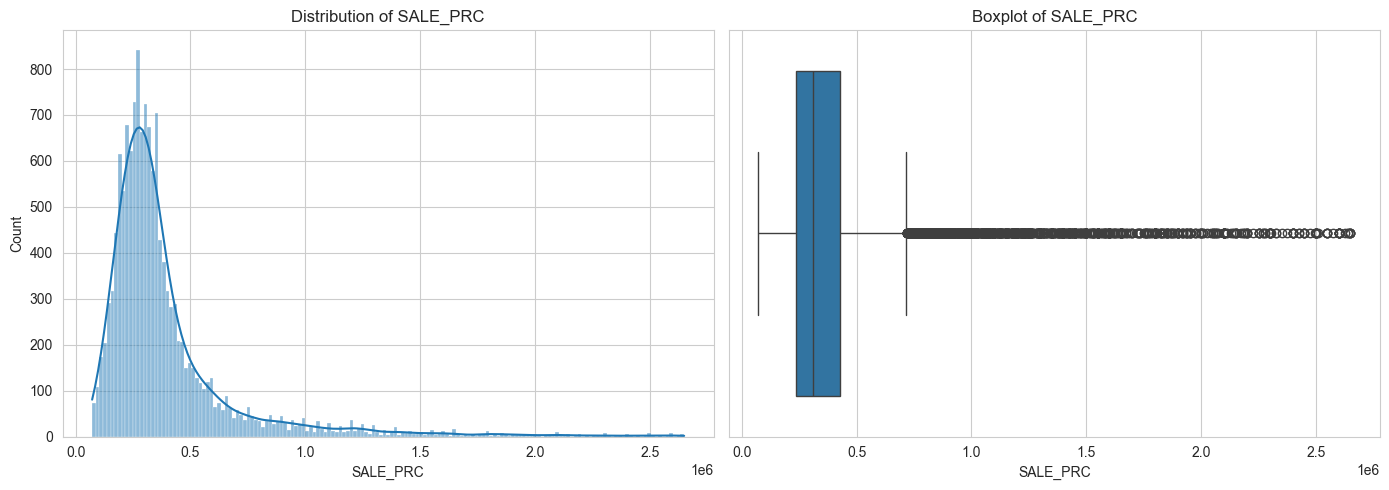

Skewness of SALE_PRC: 3.22


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['SALE_PRC'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of SALE_PRC')

sns.boxplot(x=df['SALE_PRC'], ax=axes[1])
axes[1].set_title('Boxplot of SALE_PRC')

plt.tight_layout()
plt.show()

print(f"Skewness of SALE_PRC: {df['SALE_PRC'].skew():.2f}")


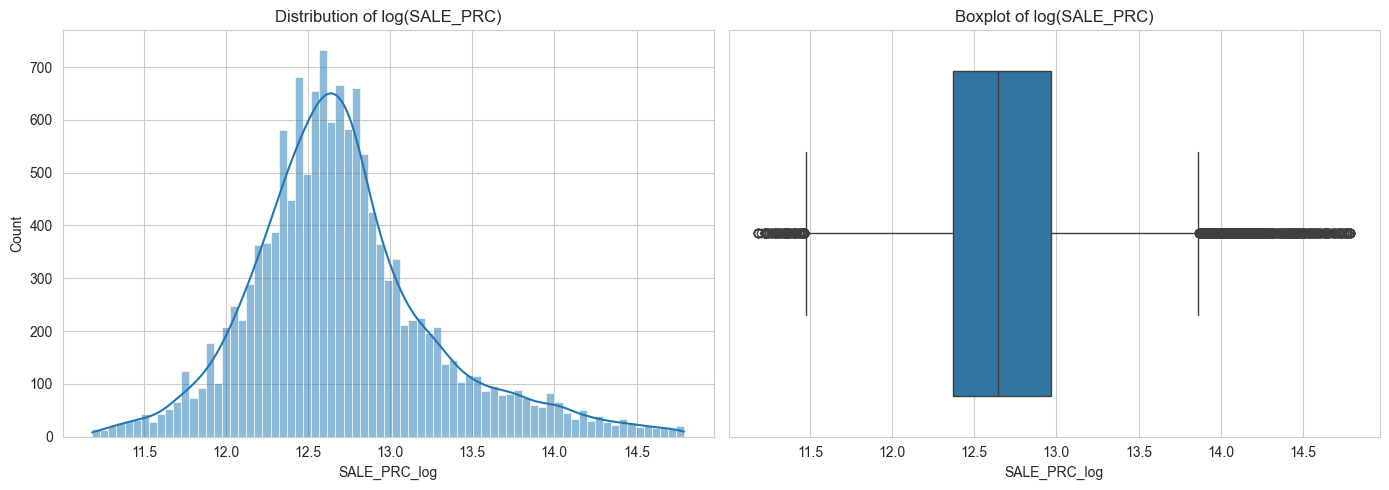

Skewness of log(SALE_PRC): 0.74


In [10]:
# Compare against a log-transformed version
df['SALE_PRC_log'] = np.log1p(df['SALE_PRC'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['SALE_PRC_log'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of log(SALE_PRC)')

sns.boxplot(x=df['SALE_PRC_log'], ax=axes[1])
axes[1].set_title('Boxplot of log(SALE_PRC)')

plt.tight_layout()
plt.show()

print(f"Skewness of log(SALE_PRC): {df['SALE_PRC_log'].skew():.2f}")


**What to note down:**
- The skewness value of `SALE_PRC` before transformation (a value well above 1 confirms strong right-skew).
- The skewness value after the log transform — it should be much closer to 0.
- Decide and record whether you will model `SALE_PRC` directly or `log(SALE_PRC)` in Assignment 2 — this is a modelling decision you must justify in your report, and it affects how you interpret error metrics later (RMSE in log-dollars vs. raw dollars).


## Step 5: Univariate Analysis of Numeric Features

We plot the distribution of each numeric predictor individually. This reveals skewness, unusual spikes, or unexpected value ranges in features such as living area, land area, and the various distance measures, which will inform later decisions on transformation and outlier handling.


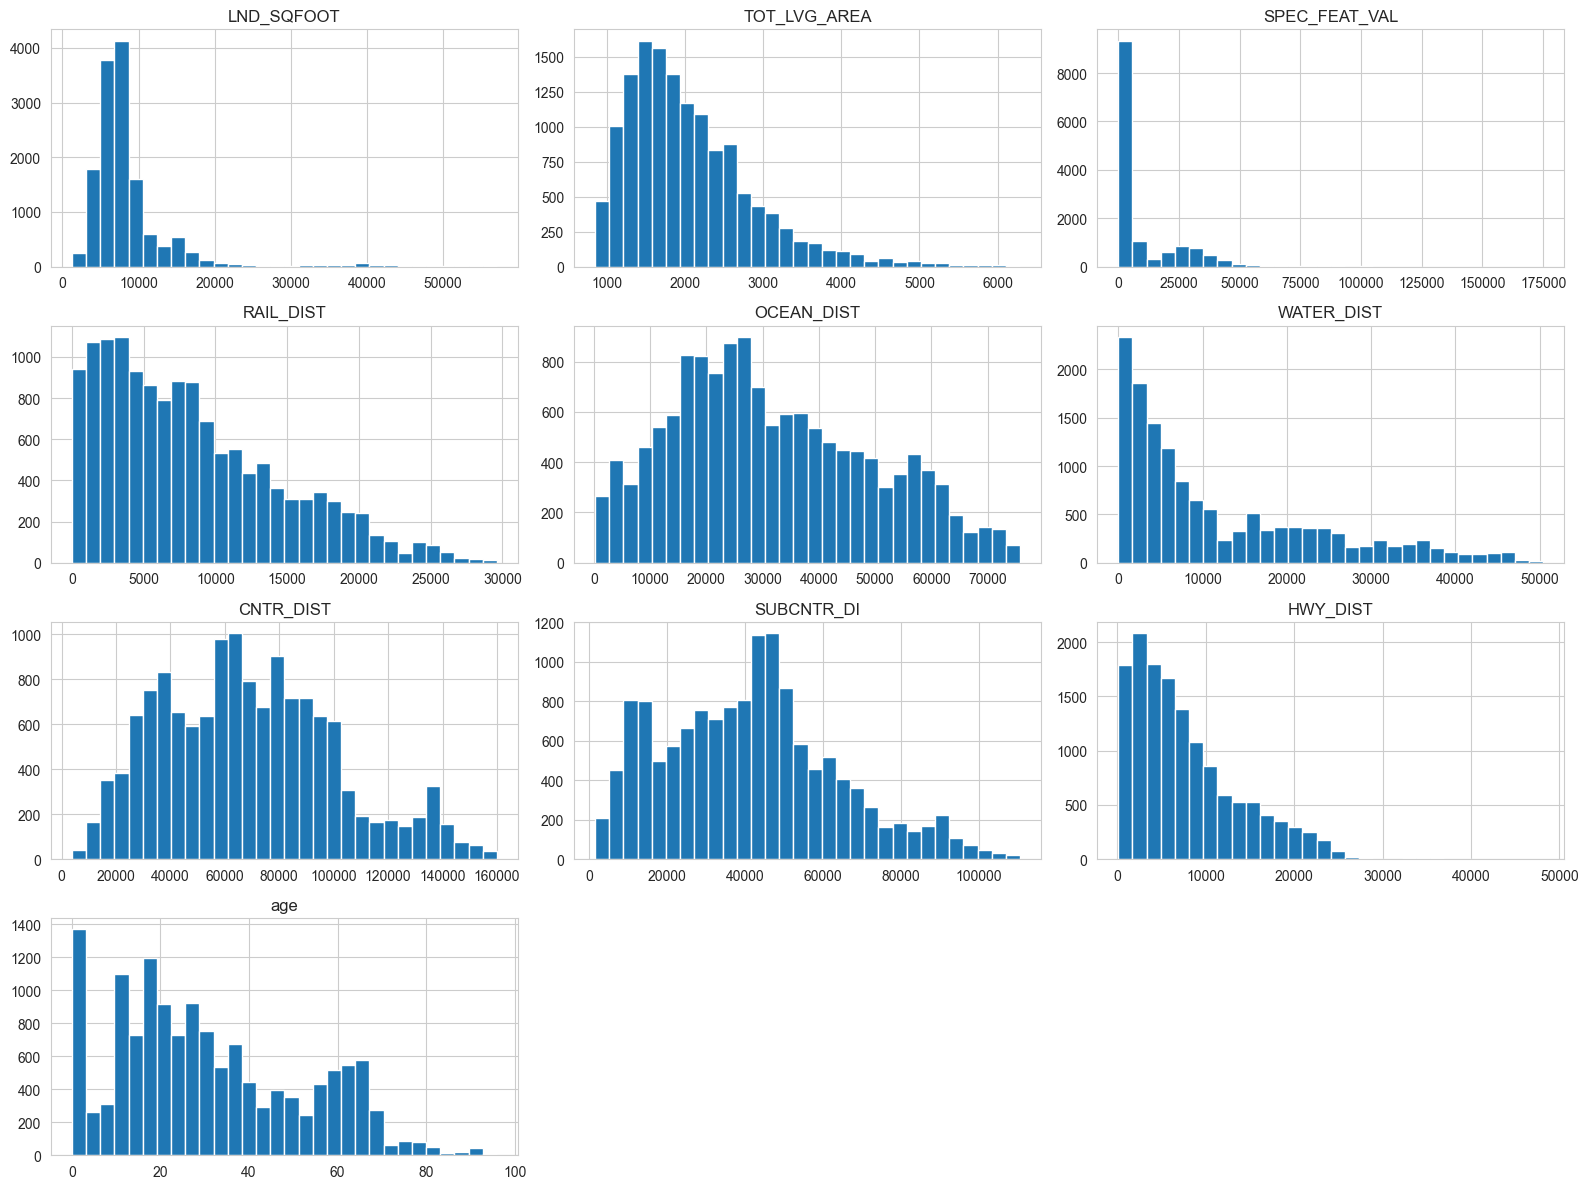

In [11]:
numeric_cols = ['LND_SQFOOT', 'TOT_LVG_AREA', 'SPEC_FEAT_VAL', 'RAIL_DIST',
                'OCEAN_DIST', 'WATER_DIST', 'CNTR_DIST', 'SUBCNTR_DI',
                'HWY_DIST', 'age']

df[numeric_cols].hist(bins=30, figsize=(16, 12))
plt.tight_layout()
plt.show()


In [12]:
skew_summary = df[numeric_cols].skew().sort_values(ascending=False)
print("Skewness of numeric features (sorted, highest first):")
skew_summary


Skewness of numeric features (sorted, highest first):


LND_SQFOOT       3.830115
SPEC_FEAT_VAL    1.902250
TOT_LVG_AREA     1.346930
WATER_DIST       1.138049
HWY_DIST         1.116250
RAIL_DIST        0.824282
age              0.505014
SUBCNTR_DI       0.454150
CNTR_DIST        0.427598
OCEAN_DIST       0.393140
dtype: float64

**What to note down:**
- Which features show strong right-skew (skewness > 1) — likely candidates: `SPEC_FEAT_VAL` (many properties have $0 special features), `LND_SQFOOT`, and possibly some distance variables.
- Any feature with a distribution that looks bimodal or has a large spike at a single value (e.g. many properties at exactly 0 for `SPEC_FEAT_VAL`) — this is worth commenting on in your report as a genuine data characteristic, not an error.


## Step 6: Outlier Detection (IQR Method)

We use the Interquartile Range (IQR) method to systematically flag potential outliers in key numeric columns. Outliers can disproportionately influence neural network training, so we need to identify them and make an explicit, justified decision on how to handle each one (cap, remove, or retain).


In [13]:
def iqr_outlier_summary(data, columns):
    summary = []
    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        n_outliers = ((data[col] < lower) | (data[col] > upper)).sum()
        summary.append({
            'feature': col, 'lower_bound': lower, 'upper_bound': upper,
            'n_outliers': n_outliers, 'pct_outliers': n_outliers / len(data) * 100
        })
    return pd.DataFrame(summary).sort_values('pct_outliers', ascending=False)

outlier_report = iqr_outlier_summary(df, numeric_cols + ['SALE_PRC'])
outlier_report


,feature,lower_bound,upper_bound,n_outliers,pct_outliers
2,SPEC_FEAT_VAL,-16503.3750,29665.6250,1703,12.223658
0,LND_SQFOOT,-189.3750,14715.6250,1370,9.833477
10,SALE_PRC,-54500.0000,717500.0000,1340,9.618145
1,TOT_LVG_AREA,-31.5000,3972.5000,447,3.208441
8,HWY_DIST,-8785.9875,22638.3125,291,2.088717
5,WATER_DIST,-22110.3750,43986.2250,245,1.758541
3,RAIL_DIST,-9905.2750,25307.3250,137,0.983348
7,SUBCNTR_DI,-20933.4375,98879.0625,120,0.861326
6,CNTR_DIST,-26979.7375,159161.1625,3,0.021533
9,age,-34.0000,94.0000,3,0.021533


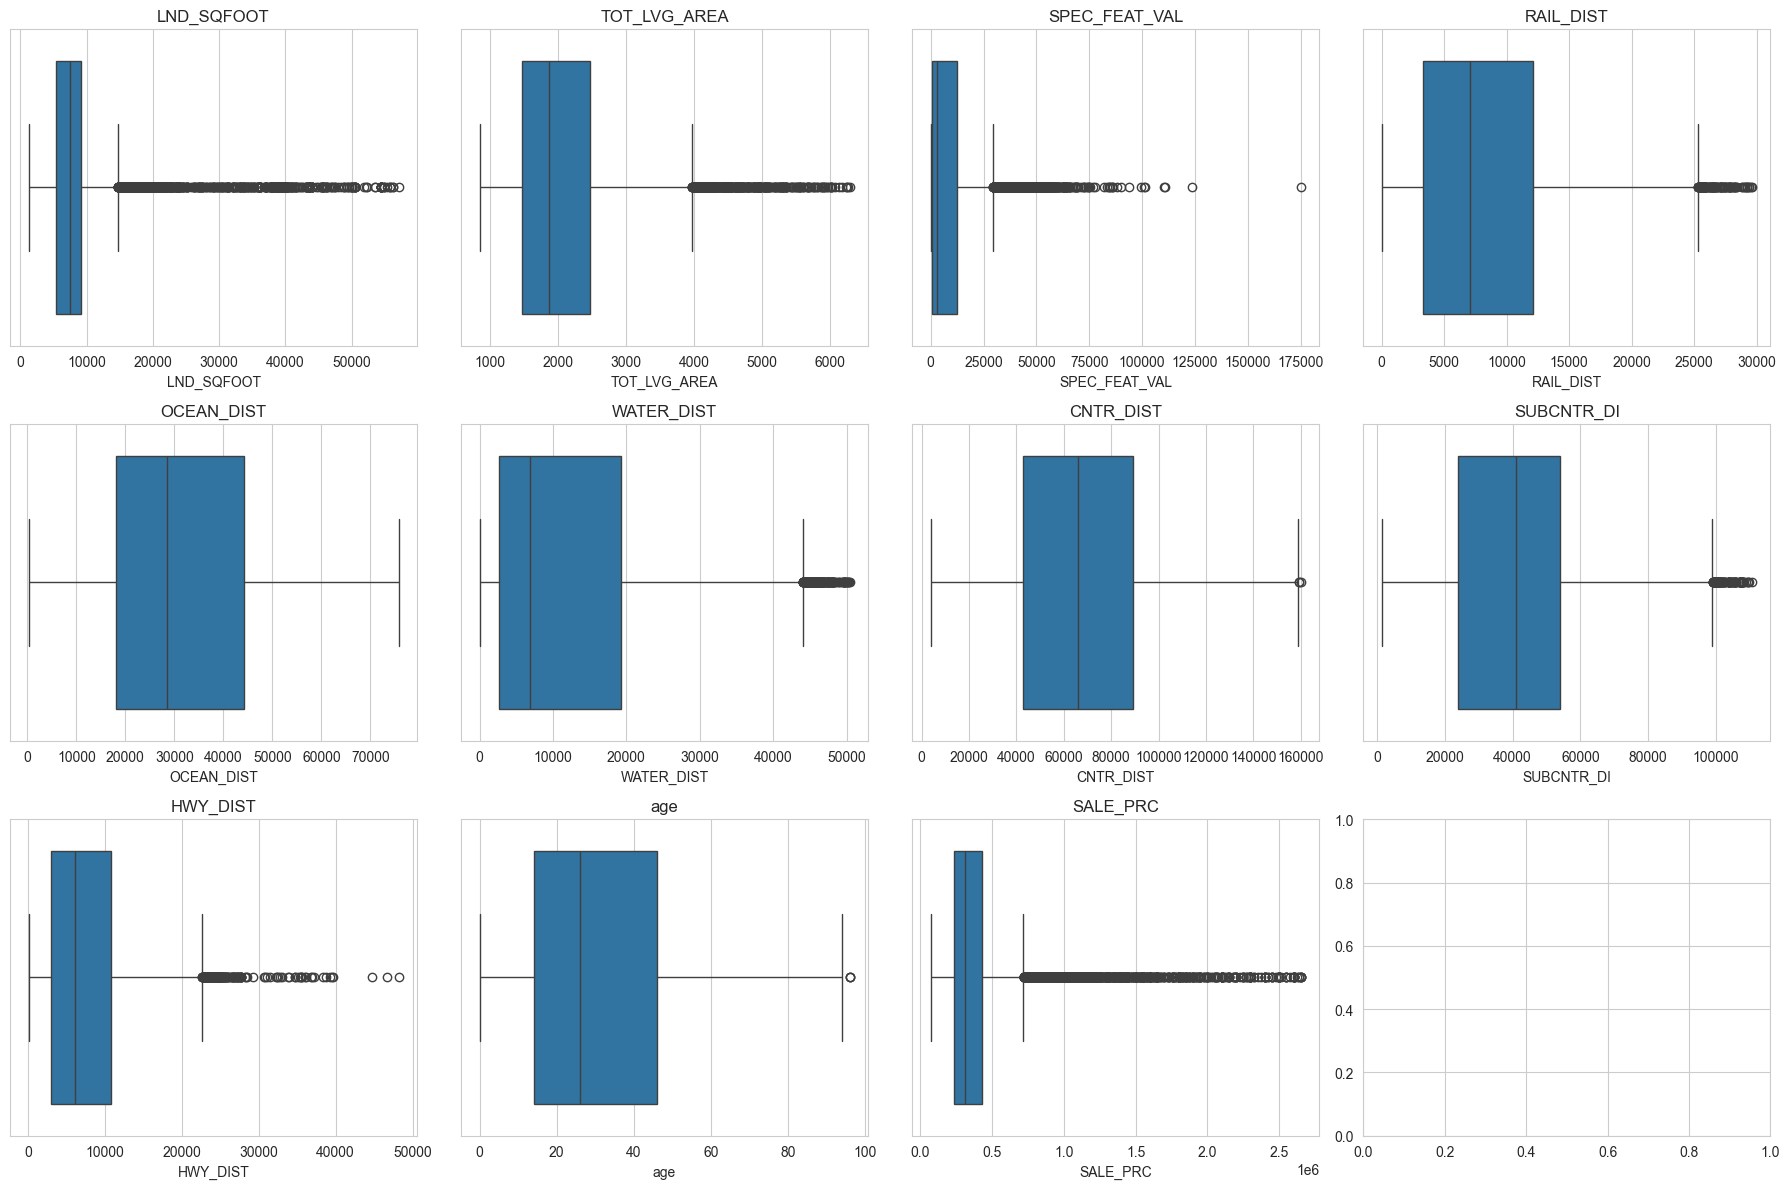

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_cols + ['SALE_PRC']):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()


**What to note down:**
- Which features have the highest percentage of IQR outliers — this often includes `SALE_PRC` and `SPEC_FEAT_VAL` in real estate data.
- Decide your handling strategy per feature and justify it: e.g. **cap** extreme SALE_PRC values at a percentile (e.g. 1st/99th) rather than deleting rows outright (to avoid losing valid high-end sales), or **retain** outliers if they represent genuine luxury properties relevant to the prediction task.
- Record how many rows (if any) are affected by your chosen strategy.


## Step 7: Correlation & Multicollinearity Analysis

We examine how numeric features correlate with `SALE_PRC` and with each other. This tells us which features are likely to be the strongest predictors, and flags multicollinearity (e.g. between the various distance measures), which is useful context even though neural networks are more robust to multicollinearity than linear models.


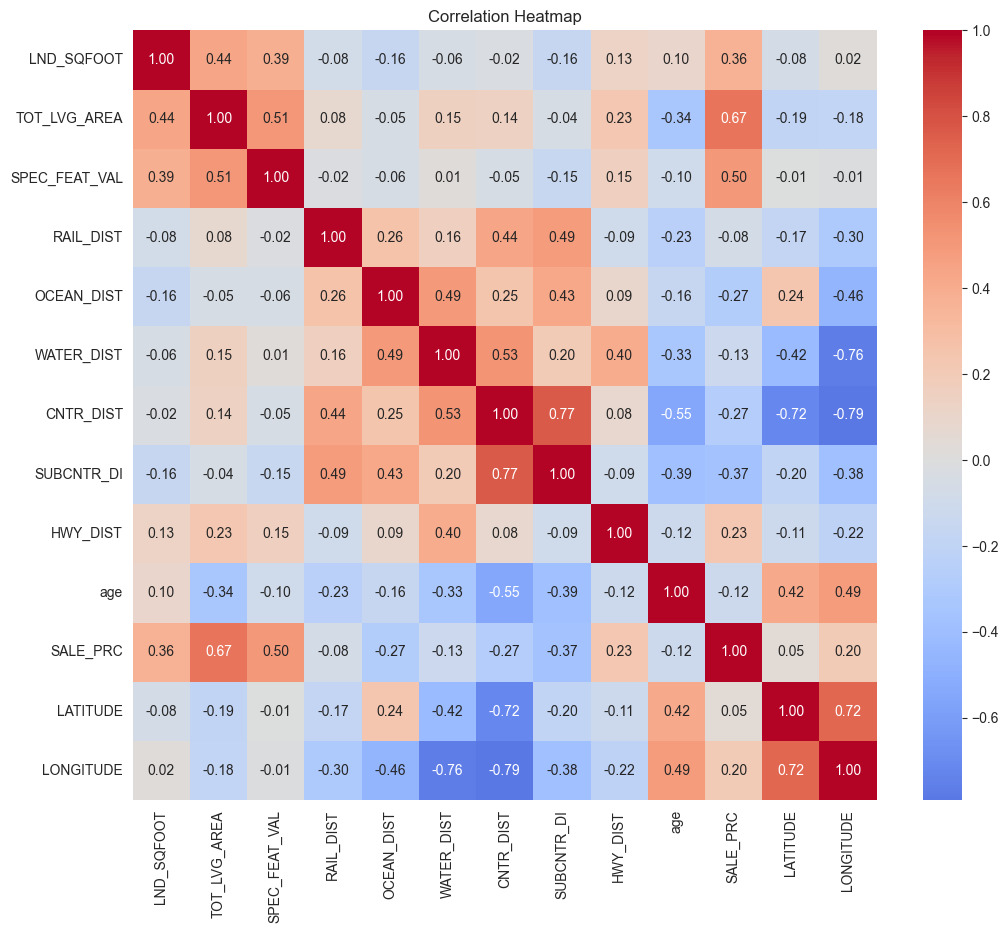

In [15]:
corr_cols = numeric_cols + ['SALE_PRC', 'LATITUDE', 'LONGITUDE']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()


In [16]:
price_corr = corr_matrix['SALE_PRC'].drop('SALE_PRC').sort_values(key=abs, ascending=False)
print("Feature correlation with SALE_PRC (sorted by strength):")
price_corr


Feature correlation with SALE_PRC (sorted by strength):


TOT_LVG_AREA     0.667301
SPEC_FEAT_VAL    0.497500
SUBCNTR_DI      -0.370078
LND_SQFOOT       0.363077
OCEAN_DIST      -0.274675
CNTR_DIST       -0.271425
HWY_DIST         0.231877
LONGITUDE        0.195274
WATER_DIST      -0.127938
age             -0.123408
RAIL_DIST       -0.077009
LATITUDE         0.047701
Name: SALE_PRC, dtype: float64

**What to note down:**
- The top 3–5 features most strongly correlated with `SALE_PRC` (likely candidates: `TOT_LVG_AREA`, `OCEAN_DIST`, `CNTR_DIST`) — these will be a key talking point in your Task 2 discussion and later in Assignment 2's evaluation.
- Any pair of distance variables that are highly correlated with each other (e.g. `CNTR_DIST` and `SUBCNTR_DI`) — note this as multicollinearity, and mention that while it doesn't invalidate a neural network approach, it is worth being aware of when interpreting feature importance.
- Whether `OCEAN_DIST` shows a negative correlation with price (expected: closer to the ocean → higher price), which ties directly back to the hedonic pricing literature discussed in Section 5.


## Step 8: Categorical, Ordinal & Binary Feature Analysis

We separately examine `avno60plus` (binary noise indicator), `structure_quality` (ordinal rating), and `month_sold` (temporal). These are not continuous numeric features, so they need a different kind of visual check — count plots rather than histograms — and a decision on how each should be encoded for the neural network.


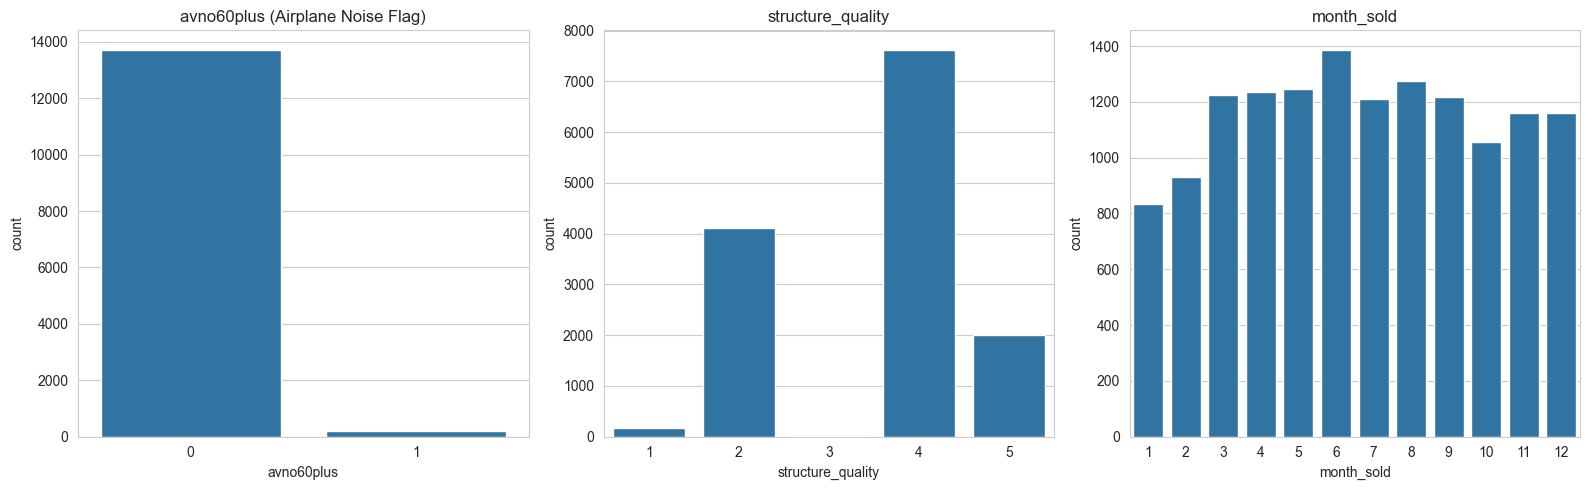

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(x='avno60plus', data=df, ax=axes[0])
axes[0].set_title('avno60plus (Airplane Noise Flag)')

sns.countplot(x='structure_quality', data=df, ax=axes[1])
axes[1].set_title('structure_quality')

sns.countplot(x='month_sold', data=df, ax=axes[2])
axes[2].set_title('month_sold')

plt.tight_layout()
plt.show()


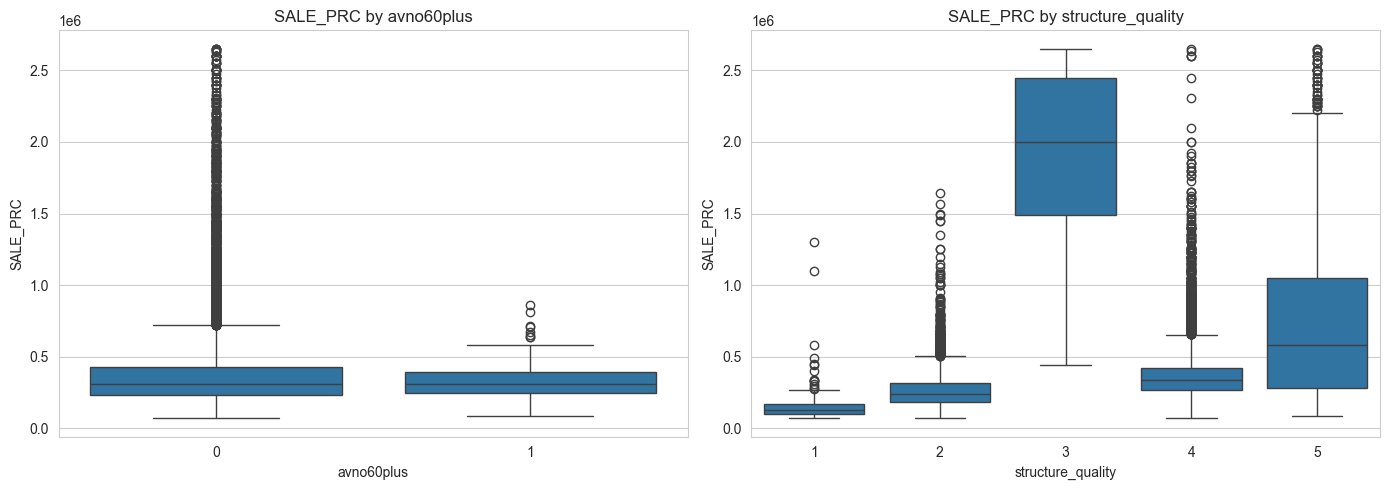

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x='avno60plus', y='SALE_PRC', data=df, ax=axes[0])
axes[0].set_title('SALE_PRC by avno60plus')

sns.boxplot(x='structure_quality', y='SALE_PRC', data=df, ax=axes[1])
axes[1].set_title('SALE_PRC by structure_quality')

plt.tight_layout()
plt.show()


**What to note down:**
- Whether `avno60plus` is heavily imbalanced (e.g. very few properties flagged 1) — if so, note this, as it affects how much predictive weight this feature can realistically carry.
- Whether `SALE_PRC` visibly decreases for properties flagged `avno60plus = 1` — if so, this is a nice direct real-world confirmation of the Nelson (2004) airport noise finding from your literature review.
- Whether higher `structure_quality` categories show a clear upward trend in `SALE_PRC` — expected and worth confirming with data before modelling.
- Any imbalance in `month_sold` (e.g. more sales in certain months) — briefly note but this is likely a minor factor.


## Step 9: Feature Engineering & Dropping Irrelevant Columns

We remove columns that provide no predictive value (`PARCELNO` is just an identifier) and optionally engineer new features. Removing identifier columns prevents the model from learning spurious patterns from what is essentially a row index.


In [19]:
# Drop the identifier column — it carries no predictive information
df_model = df.drop(columns=['PARCELNO'])

# Optional feature engineering example: average distance to the two nearest commercial centres
df_model['AVG_CNTR_DIST'] = df_model[['CNTR_DIST', 'SUBCNTR_DI']].mean(axis=1)

df_model.head()


,LATITUDE,LONGITUDE,SALE_PRC,LND_SQFOOT,TOT_LVG_AREA,SPEC_FEAT_VAL,RAIL_DIST,OCEAN_DIST,WATER_DIST,CNTR_DIST,SUBCNTR_DI,HWY_DIST,age,avno60plus,month_sold,structure_quality,SALE_PRC_log,AVG_CNTR_DIST
0,25.891031,-80.160561,440000.0,9375,1753,0,2815.9,12811.4,347.6,42815.3,37742.2,15954.9,67,0,8,4,12.994532,40278.75
1,25.891324,-80.153968,349000.0,9375,1715,0,4359.1,10648.4,337.8,43504.9,37340.5,18125.0,63,0,9,4,12.762830,40422.70
2,25.891334,-80.153740,800000.0,9375,2276,49206,4412.9,10574.1,297.1,43530.4,37328.7,18200.5,61,0,2,4,13.592368,40429.55
3,25.891765,-80.152657,988000.0,12450,2058,10033,4585.0,10156.5,0.0,43797.5,37423.2,18514.4,63,0,9,4,13.803439,40610.35
4,25.891825,-80.154639,755000.0,12800,1684,16681,4063.4,10836.8,326.6,43599.7,37550.8,17903.4,42,0,7,4,13.534474,40575.25


**What to note down:**
- Confirm the final list of columns going into modelling (print `df_model.columns.tolist()` for your report).
- If you created any engineered feature (like `AVG_CNTR_DIST` above), briefly justify why — e.g. "this combines two related distance measures into a single accessibility indicator, which may reduce multicollinearity between them."
- This step is a good place to also decide: will you keep raw `LATITUDE`/`LONGITUDE`, drop them (since distance features already encode location), or use them for a geographic visualisation only? State and justify your choice.


## Step 10: Encoding Categorical Features

Although `avno60plus` and `structure_quality` are already stored as numbers, we confirm they are treated correctly (binary and ordinal respectively) rather than blindly one-hot encoding them, which would be unnecessary here and would only add redundant columns.


In [20]:
print("avno60plus unique values:", sorted(df_model['avno60plus'].unique()))
print("structure_quality unique values:", sorted(df_model['structure_quality'].unique()))

# Both are already numeric and suitable for direct use as model inputs.
# No one-hot encoding is required since there are no free-text / nominal categorical columns
# in this dataset (all remaining columns are numeric, binary, or ordinal).


avno60plus unique values: [np.int64(0), np.int64(1)]
structure_quality unique values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


**What to note down:**
- Confirm and state explicitly in your report: "No nominal categorical encoding (e.g. one-hot encoding) was required, as `avno60plus` is already binary and `structure_quality` is already an ordinal numeric rating." This is a valid and expected finding — not every dataset needs this step, but you must show you checked.


## Step 11: Train / Validation / Test Split

We split the data **before** scaling to prevent data leakage (i.e. the scaler must only "see" training data statistics, not the validation/test sets). A 70/15/15 split is used here, giving separate sets for training, hyperparameter tuning (Assignment 2, Task 2), and final unbiased evaluation.


In [21]:
X = df_model.drop(columns=['SALE_PRC', 'SALE_PRC_log'])
y = df_model['SALE_PRC']  # switch to df_model['SALE_PRC_log'] here if you decided to model log-price

# First split off the test set (15%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Then split the remaining 85% into train (70% overall) and validation (15% overall)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1765, random_state=42  # 0.1765 * 0.85 ≈ 0.15
)

print(f"Train set: {X_train.shape[0]} rows ({X_train.shape[0]/len(df_model)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]} rows ({X_val.shape[0]/len(df_model)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]} rows ({X_test.shape[0]/len(df_model)*100:.1f}%)")


Train set: 9751 rows (70.0%)
Validation set: 2091 rows (15.0%)
Test set: 2090 rows (15.0%)


**What to note down:**
- The exact row counts and percentages for each split — include this in your report to demonstrate the 70/15/15 ratio was achieved.
- Confirm you used a fixed `random_state` for reproducibility — mention this explicitly, as reproducibility is a marker of good practice.
- Reference Retnowati et al. (2024) from your literature review here: they found a 60:20:20 split performed best in their study, so you can justify your own ratio choice (70:15:15 vs. their 60:20:20) based on your larger dataset size affording more training data while still leaving adequate validation/test data.


## Step 12: Feature Scaling

Neural networks train more effectively and converge faster when input features are on a similar scale. We fit a `StandardScaler` on the **training data only**, then apply the same transformation to the validation and test sets, ensuring no information from those sets leaks into the scaling parameters.


In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrame for readability
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(X_val_scaled, columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

X_train_scaled.describe().T[['mean', 'std']]


,mean,std
LATITUDE,1.880377e-15,1.000051
LONGITUDE,-2.475131e-14,1.000051
LND_SQFOOT,9.108588e-17,1.000051
TOT_LVG_AREA,1.034736e-16,1.000051
SPEC_FEAT_VAL,1.457374e-18,1.000051
RAIL_DIST,9.691538e-17,1.000051
OCEAN_DIST,2.943896e-16,1.000051
WATER_DIST,-1.675980e-17,1.000051
CNTR_DIST,2.462962e-16,1.000051
SUBCNTR_DI,-2.295364e-16,1.000051


**What to note down:**
- Confirm that after scaling, the training set's feature means are ~0 and standard deviations are ~1 (shown in the output above) — this is the expected result of `StandardScaler` and confirms it was applied correctly.
- Explicitly state in your report that the scaler was fit on training data only, to demonstrate awareness of data leakage — this is a good-practice point markers look for.


## Step 13: Save Prepared Datasets

Finally, we save the processed train/validation/test sets to disk as CSV files. This means Assignment 2's model-building notebook can simply load these ready-made files, keeping the two assignments cleanly separated while ensuring identical pre-processing is used for every model.


In [23]:
X_train_scaled.to_csv('X_train.csv', index=False)
X_val_scaled.to_csv('X_val.csv', index=False)
X_test_scaled.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_val.to_csv('y_val.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

print("All prepared datasets saved successfully.")


All prepared datasets saved successfully.


**What to note down:**
- List the final files saved and confirm their row counts match the splits from Step 11.
- This is a natural point to write your Task 2 summary paragraph for the report: briefly recap every decision made (duplicate handling, missing values, outlier treatment, feature engineering, encoding, scaling, and split ratio) in 4–6 sentences, as a clean closing summary before moving into Assignment 2.
